# Notebook 01: Impurity Geometry (Entropy vs. Gini), Information Gain & Recursive Partitioning

In this notebook we explore:
1. **Mathematical Comparison of Node Impurity Criteria:** Plotting Shannon Entropy $H(p) = -p\log_2 p - (1-p)\log_2(1-p)$, Scaled Entropy (0.5 H(p)), Gini Impurity $G(p) = 2p(1-p)$, and Misclassification Error $\min(p, 1-p)$ across $p \in [0, 1]$.
2. **Continuous Split Threshold Sweep:** Evaluating exact Information Gain $\mathrm{IG}(S, j, t)$ across all adjacent midpoints $t = \frac{v_i + v_{i+1}}{2}$.
3. **One-Hot Encoding of Categorical Features:** Splitting discrete categorical attributes cleanly using `OneHotEncoderScratch`.
4. **Recursive Axis-Aligned Feature Space Partitioning:** Visualizing how tree depths $D \in \{1, 2, 4, 10\}$ progressively slice $\mathbb{R}^2$ into hyper-rectangles.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.plot_theme import (
    AMBER,
    CORAL,
    CYAN,
    EMERALD,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    plot_decision_boundary,
    save_fig,
)
from src.trees_engine import (
    DecisionTreeClassifierScratch,
    OneHotEncoderScratch,
    entropy_impurity,
    gini_impurity,
)

apply_github_dark_style()

## 1. Impurity Functions & Continuous Midpoint Split Search (`01_gini_vs_entropy_impurity_curve.png`)

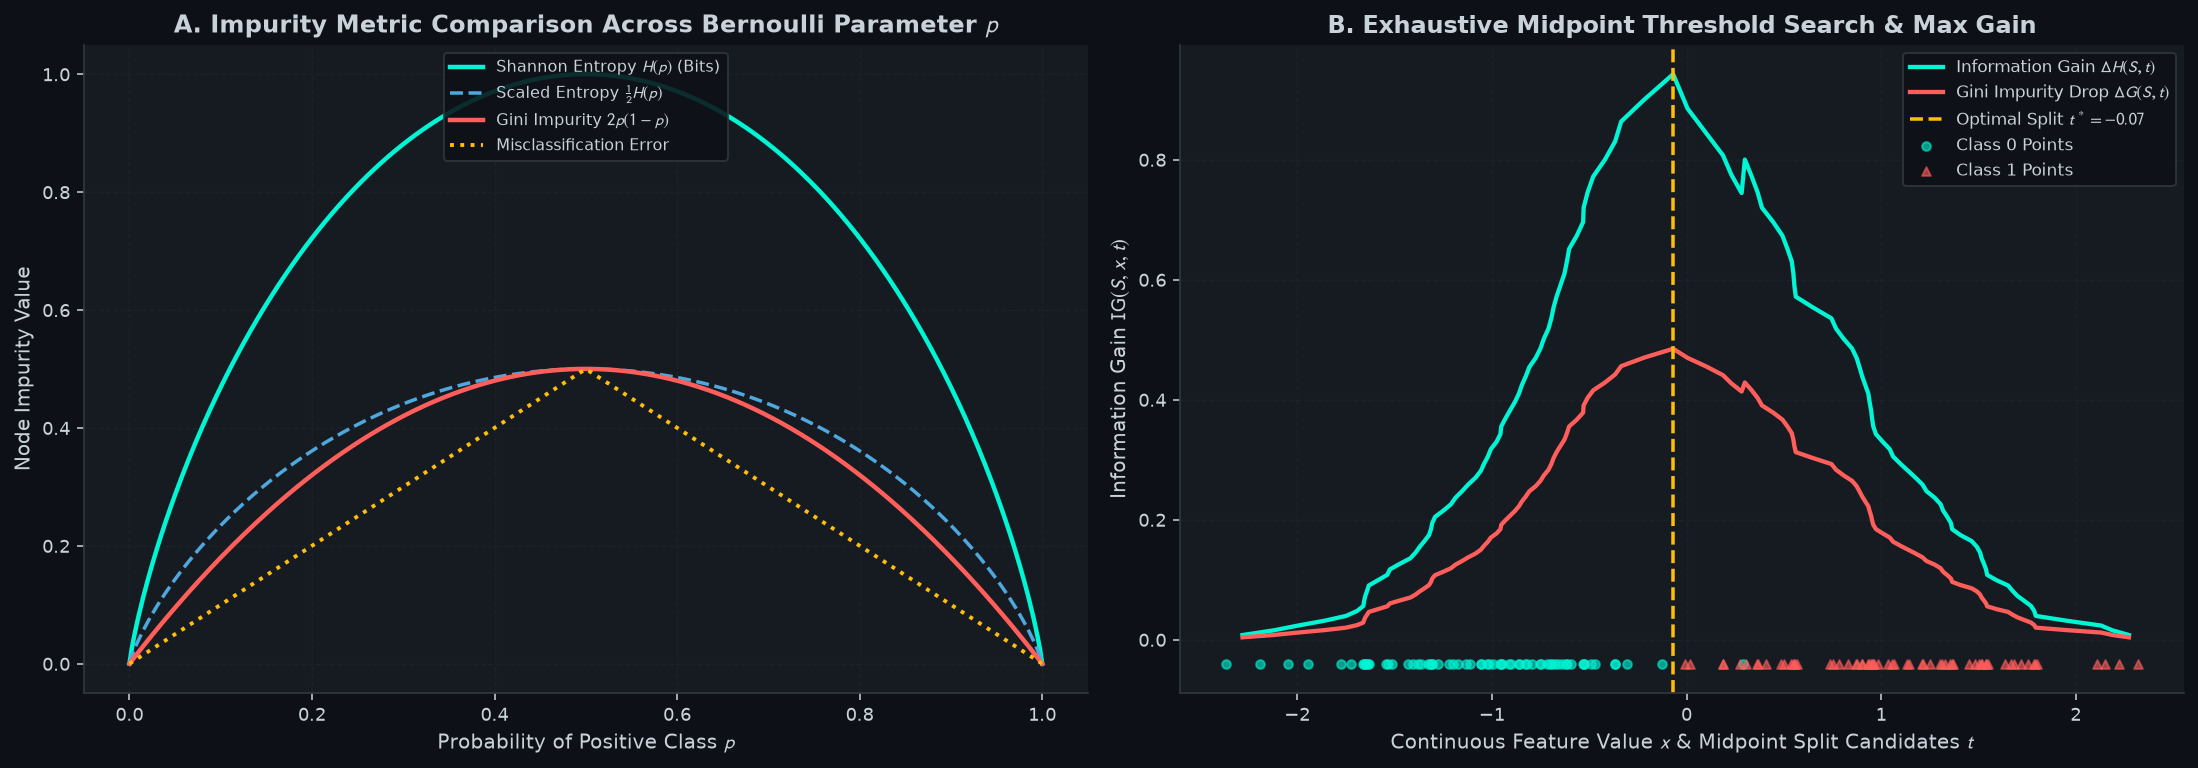

In [2]:
p_vals = np.linspace(1e-6, 1.0 - 1e-6, 400)
entropy_curve = -p_vals * np.log2(p_vals) - (1.0 - p_vals) * np.log2(1.0 - p_vals)
scaled_entropy = 0.5 * entropy_curve
gini_curve = 2.0 * p_vals * (1.0 - p_vals)
misclass_curve = np.minimum(p_vals, 1.0 - p_vals)

# Generate a 1D continuous feature with two noisy clusters to sweep split thresholds t
rng = np.random.default_rng(42)
x_cont = np.concatenate([rng.normal(-1.1, 0.65, 65), rng.normal(1.2, 0.70, 65)])
y_cont = np.concatenate([np.zeros(65, dtype=np.int64), np.ones(65, dtype=np.int64)])

uniq_x = np.unique(x_cont)
midpoints = 0.5 * (uniq_x[:-1] + uniq_x[1:])
ig_entropy = []
ig_gini = []
base_ent = entropy_impurity(y_cont)
base_gini = gini_impurity(y_cont)

for t in midpoints:
    left_m = x_cont <= t
    right_m = ~left_m
    w_l = np.mean(left_m)
    w_r = 1.0 - w_l
    ig_entropy.append(base_ent - (w_l * entropy_impurity(y_cont[left_m]) + w_r * entropy_impurity(y_cont[right_m])))
    ig_gini.append(base_gini - (w_l * gini_impurity(y_cont[left_m]) + w_r * gini_impurity(y_cont[right_m])))

best_idx_ent = np.argmax(ig_entropy)
best_split_x = midpoints[best_idx_ent]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.8, 5.6))

# Panel A: Impurity Metric Curves
ax1.plot(p_vals, entropy_curve, color=CYAN, linewidth=2.3, label="Shannon Entropy $H(p)$ (Bits)")
ax1.plot(p_vals, scaled_entropy, color=SLATE_BLUE, linestyle="--", linewidth=1.8, label=r"Scaled Entropy $\frac{1}{2}H(p)$")
ax1.plot(p_vals, gini_curve, color=CORAL, linewidth=2.3, label="Gini Impurity $2p(1-p)$")
ax1.plot(p_vals, misclass_curve, color=AMBER, linestyle=":", linewidth=2.0, label="Misclassification Error")
ax1.set_xlabel("Probability of Positive Class $p$")
ax1.set_ylabel("Node Impurity Value")
ax1.set_title("A. Impurity Metric Comparison Across Bernoulli Parameter $p$")
ax1.legend(loc="upper center", fontsize=8.4)

# Panel B: Midpoint Threshold Sweep
ax2.plot(midpoints, ig_entropy, color=CYAN, linewidth=2.2, label=r"Information Gain $\Delta H(S, t)$")
ax2.plot(midpoints, ig_gini, color=CORAL, linewidth=2.2, label=r"Gini Impurity Drop $\Delta G(S, t)$")
ax2.axvline(best_split_x, color=AMBER, linestyle="--", linewidth=1.8, label=f"Optimal Split $t^* = {best_split_x:.2f}$")
ax2.scatter(x_cont[y_cont == 0], np.full(np.sum(y_cont == 0), -0.04), color=CYAN, s=20, alpha=0.6, label="Class 0 Points")
ax2.scatter(x_cont[y_cont == 1], np.full(np.sum(y_cont == 1), -0.04), color=CORAL, marker="^", s=20, alpha=0.6, label="Class 1 Points")
ax2.set_xlabel("Continuous Feature Value $x$ & Midpoint Split Candidates $t$")
ax2.set_ylabel("Information Gain $\mathrm{IG}(S, x, t)$")
ax2.set_title("B. Exhaustive Midpoint Threshold Search & Max Gain")
ax2.legend(loc="upper right", fontsize=8.5)

fig.tight_layout()
assets_dir = Path("assets")
assets_dir.mkdir(parents=True, exist_ok=True)
save_fig(fig, assets_dir / "01_gini_vs_entropy_impurity_curve.png")
plt.show()

## 2. Categorical Features via One-Hot Encoding + Continuous Features

In [3]:
X_cat_raw = np.array([["Red"], ["Red"], ["Green"], ["Blue"], ["Blue"], ["Red"], ["Green"], ["Blue"]])
X_num_col = np.array([[1.2], [0.8], [2.5], [3.1], [0.4], [2.9], [0.5], [2.8]])
y_tab = np.array([1, 1, 0, 0, 0, 1, 0, 1])

ohe = OneHotEncoderScratch()
X_ohe = ohe.fit_transform(X_cat_raw)
X_combined = np.hstack([X_ohe, X_num_col])
tree_tab = DecisionTreeClassifierScratch(criterion="entropy", max_depth=3).fit(X_combined, y_tab)
print("One-Hot Categories Learned:", ohe.categories_[0])
print(f"Combined Categorical + Continuous Tree Accuracy: {np.mean(tree_tab.predict(X_combined) == y_tab)*100:.1f}%")

One-Hot Categories Learned: ['Blue' 'Green' 'Red']
Combined Categorical + Continuous Tree Accuracy: 100.0%


## 3. Recursive Feature Space Partitioning Across Depths $D \in \{1, 2, 4, 10\}$ (`02_recursive_feature_space_partitioning.png`)

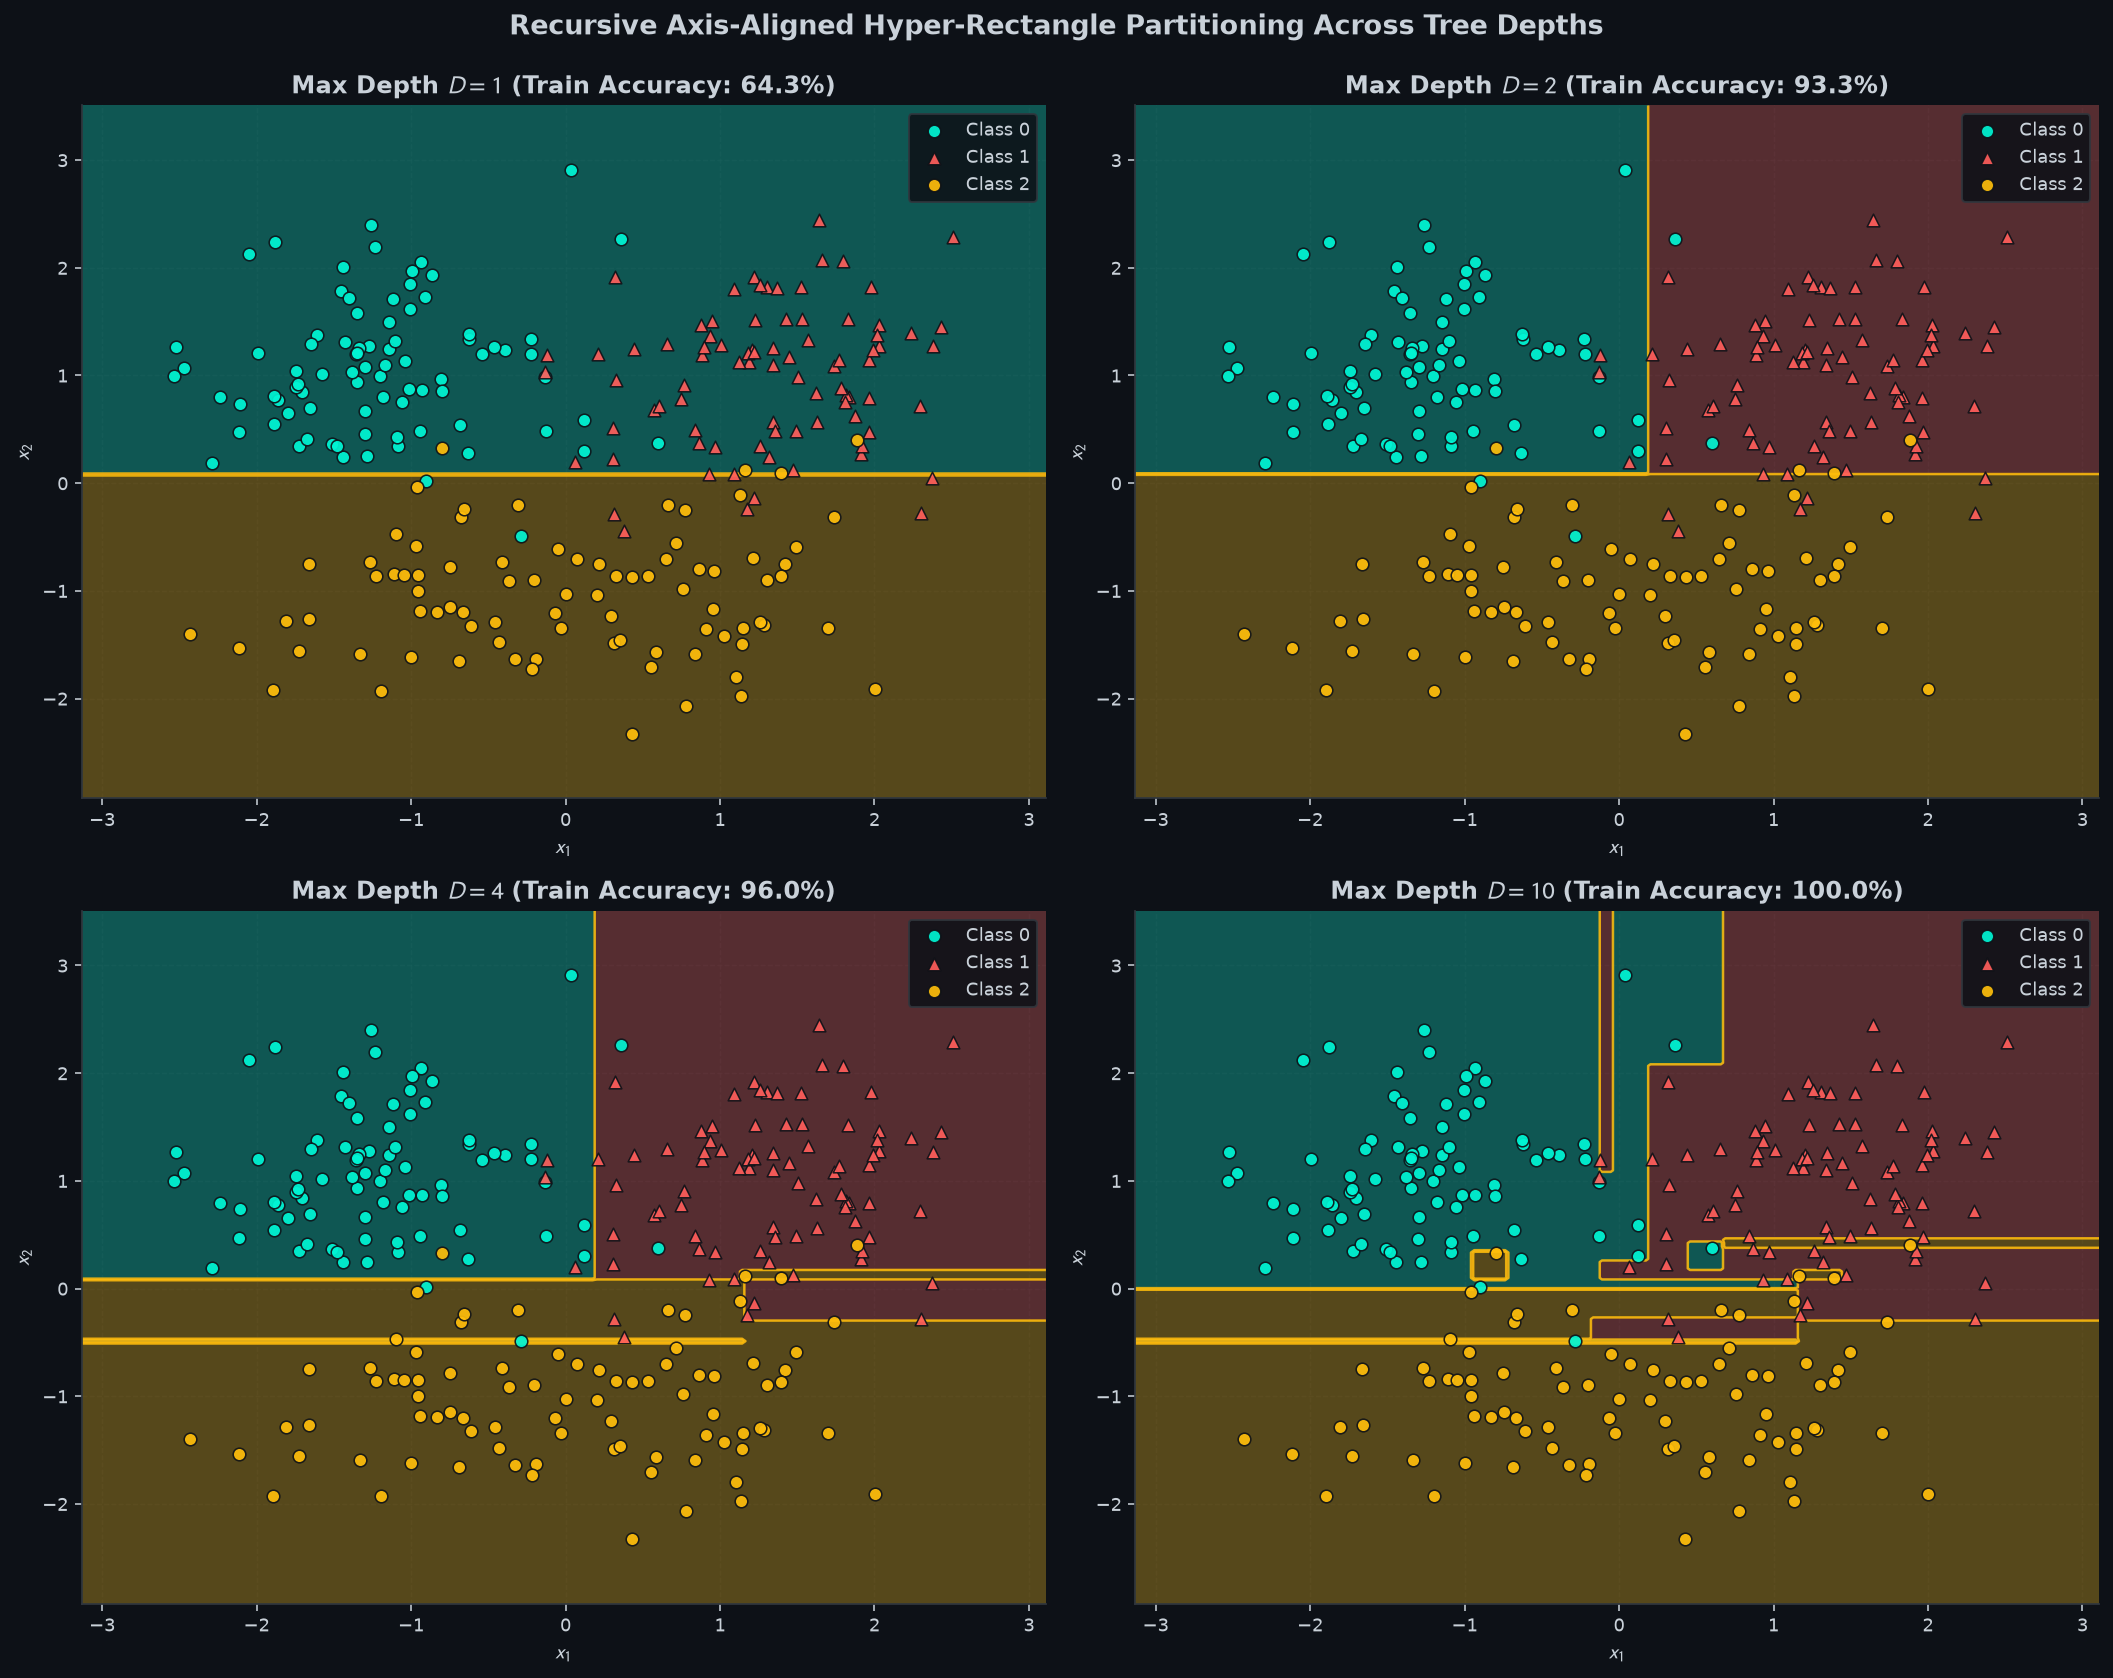

In [4]:
m_cl = 84
X_p0 = rng.normal(loc=[-1.2, 1.1], scale=0.62, size=(m_cl, 2))
X_p1 = rng.normal(loc=[1.3, 1.0], scale=0.62, size=(m_cl, 2))
X_p2 = np.vstack([
    rng.normal(loc=[-0.8, -1.1], scale=0.55, size=(m_cl // 2, 2)),
    rng.normal(loc=[1.0, -1.0], scale=0.55, size=(m_cl // 2, 2)),
])
X_part = np.vstack([X_p0, X_p1, X_p2])
y_part = np.concatenate([np.zeros(m_cl, dtype=int), np.ones(m_cl, dtype=int), np.full(m_cl, 2, dtype=int)])

depths_to_plot = [1, 2, 4, 10]
fig, axes = plt.subplots(2, 2, figsize=(15.2, 12.0))

for ax, d_max in zip(axes.ravel(), depths_to_plot):
    clf_d = DecisionTreeClassifierScratch(criterion="gini", max_depth=d_max, min_samples_split=2).fit(X_part, y_part)
    acc_d = float(np.mean(clf_d.predict(X_part) == y_part))
    plot_decision_boundary(
        predict_fn=lambda grid, m_tree=clf_d: m_tree.predict(grid),
        X=X_part,
        y=y_part,
        ax=ax,
        is_probability=False,
        title=f"Max Depth $D = {d_max}$ (Train Accuracy: {acc_d*100:.1f}%)",
    )

fig.suptitle("Recursive Axis-Aligned Hyper-Rectangle Partitioning Across Tree Depths", fontsize=14, fontweight="bold", y=0.995)
fig.tight_layout()
save_fig(fig, assets_dir / "02_recursive_feature_space_partitioning.png")
plt.show()